# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [1]:
# Twoje rozwiązanie
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
print(f"Shape: {df.shape}")
display(df.head())
display(df.describe())

Shape: (768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [2]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

Udział klas:
outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64

Jawne braki (NaN):
pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64

Liczba zer w cechach:
pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
dtype: int64


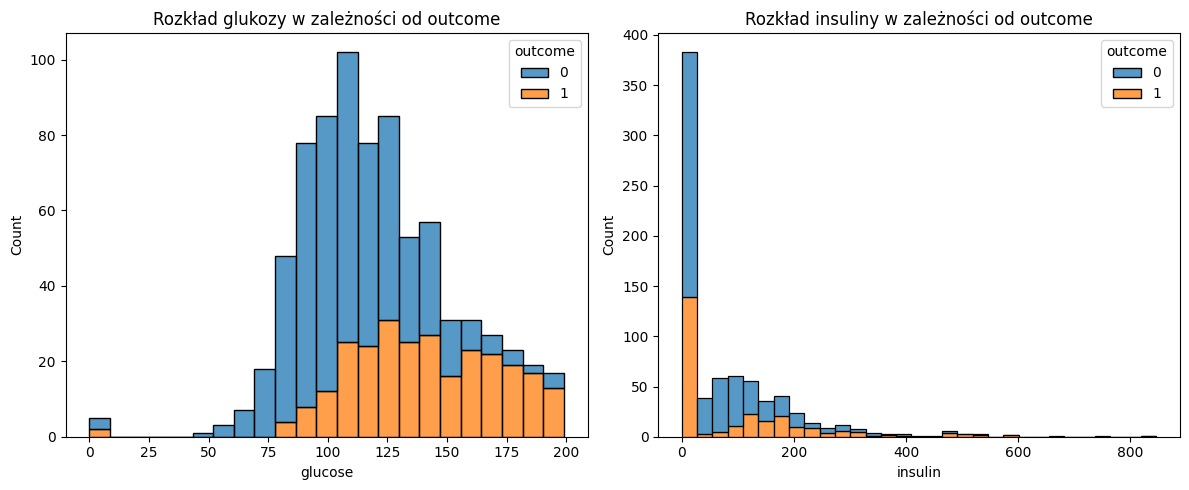

In [3]:
# Twoje rozwiązanie

class_share = df["outcome"].value_counts(normalize=True)
print("Udział klas:")
print(class_share)
print("\nJawne braki (NaN):")
print(df.isna().sum())
cechy = kolumny[:-1]
zeros = (df[cechy] == 0).sum()
print("\nLiczba zer w cechach:")
print(zeros)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose", hue="outcome", multiple="stack", ax=axes[0])
axes[0].set_title("Rozkład glukozy w zależności od outcome")
sns.histplot(data=df, x="insulin", hue="outcome", multiple="stack", ax=axes[1])
axes[1].set_title("Rozkład insuliny w zależności od outcome")
plt.tight_layout()
plt.show()

In [4]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

1. Baseline osiągnie dokładność równą udziałowi klasy większościowej, czyli około 65.1%.

2. Fizycznie niemożliwe: glucose, blood_pressure, skin_thickness, insulin, bmi, ponieważ żywy człowiek nie może mieć zerowego ciśnienia, grubości skóry, zerowej glukozy czy BMI. Zupełnie normalne: pregnancies, ponieważ kobieta mogła nigdy nie być w ciąży.

3. Z wizualizacji oraz statystyk wynika, że glucose wyraźnie różnicuje obie grupy - osoby z cukrzycą mają widocznie przesunięty rozkład w stronę wyższych wartości glukozy.

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [5]:
# Twoje rozwiązanie

kolumny_braki = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
df_clean = df.copy()
df_clean[kolumny_braki] = df_clean[kolumny_braki].replace(0, np.nan)
missing = df_clean.isna().sum()
print("Braki:")
print(missing)

Braki:
pregnancies         0
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome             0
dtype: int64


In [6]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

1. Usunięcie wierszy z brakami zmniejszyłoby rozmiar zbioru danych prawie o połowę. Mogłoby to negatywnie wpłynąć na zdolność modeli do uogólniania.
2. Usunięcie całej kolumny insulin - tracimy potencjalnie cenną cechę diagnostyczną.
3. Uzupełnienie braków - np. medianą lub średnią, lub algorytmami typu KNNImputer, IterativeImputer.

Wybieram imputację medianą w ramach potoku przetwarzania. Pozwala na zachowanie wszystkich obserwacji w zbiorze, nie usuwa ważnej cechy, a mediana jest odporna na wartości odstające występujące w rozkładzie insuliny.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [7]:
# Twoje rozwiązanie
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df_clean.drop(columns="outcome")
y = df_clean["outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
def model_z(klasyfikator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("klasyfikator", klasyfikator)
    ])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

                      CV średnia  CV odch.     train
baseline                0.651049  0.002249  0.651042
regresja logistyczna    0.777856  0.024709  0.789931
kNN                     0.736132  0.020716  0.835069
drzewo decyzyjne        0.713568  0.024244  1.000000
las losowy              0.748291  0.014015  1.000000


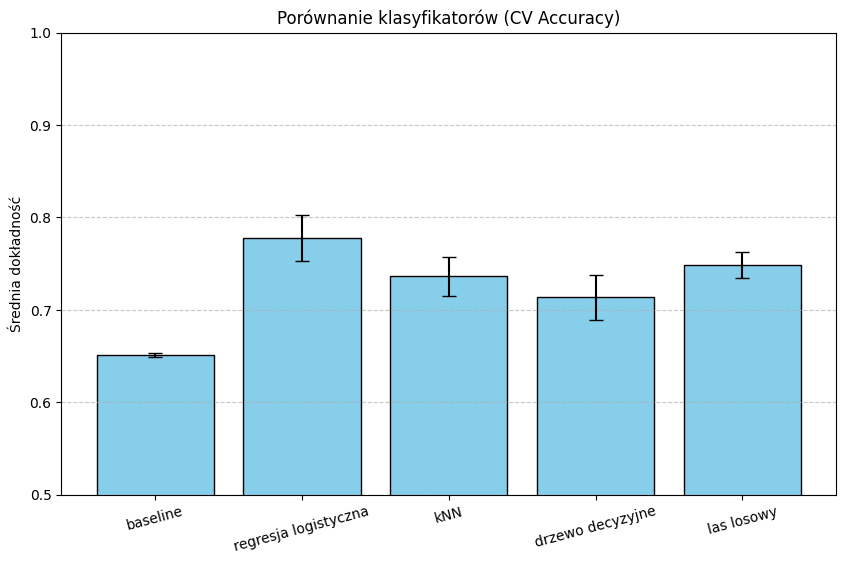

In [9]:
# Twoje rozwiązanie

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

modele = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42)
}
indeks = []
cv_srednia = []
cv_odch = []
train_acc = []
for nazwa, model in modele.items():
    pipeline = model_z(model)
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy")
    pipeline.fit(X_train, y_train)
    train_score = pipeline.score(X_train, y_train)
    indeks.append(nazwa)
    cv_srednia.append(scores.mean())
    cv_odch.append(scores.std())
    train_acc.append(train_score)

porownanie = pd.DataFrame({
    "CV średnia": cv_srednia,
    "CV odch.": cv_odch,
    "train": train_acc
}, index=indeks)
print(porownanie)
plt.figure(figsize=(10, 6))
plt.bar(porownanie.index, porownanie["CV średnia"], yerr=porownanie["CV odch."], capsize=5, color="skyblue", edgecolor="black")
plt.title("Porównanie klasyfikatorów (CV Accuracy)")
plt.ylabel("Średnia dokładność")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [10]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

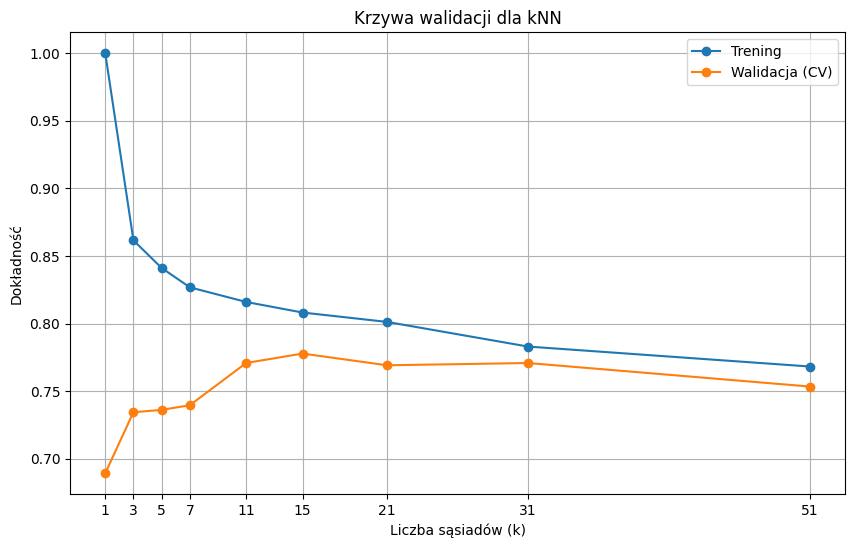

In [11]:
# Twoje rozwiązanie

from sklearn.model_selection import validation_curve
ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]
pipeline_knn = model_z(KNeighborsClassifier())
tren, walid = validation_curve(
    pipeline_knn, X_train, y_train,
    param_name="klasyfikator__n_neighbors",
    param_range=ks,
    cv=cv,
    scoring="accuracy"
)
tren_mean = tren.mean(axis=1)
walid_mean = walid.mean(axis=1)
plt.figure(figsize=(10, 6))
plt.plot(ks, tren_mean, label="Trening", marker="o")
plt.plot(ks, walid_mean, label="Walidacja (CV)", marker="o")
plt.title("Krzywa walidacji dla kNN")
plt.xlabel("Liczba sąsiadów (k)")
plt.ylabel("Dokładność")
plt.xticks(ks)
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

1. Ponieważ przy k=1 klasyfikator szuka jednego najbliższego sąsiada dla każdego punktu. W zbiorze treningowym najbliższym sąsiadem dowolnego punktu jest on sam, dlatego klasyfikacja na zbiorze treningowym jest zawsze bezbłędna.

2. Przeuczenie występuje dla małych wartości k np. 1, 3. Widzimy wtedy ogromną różnicę między bardzo wysoką dokładnością treningową a znacznie niższą dokładnością na walidacji krzyżowej. Niedouczenie pojawia się dla dużych wartości k np. 51 i więcej. Model staje się zbyt uproszczony (decyduje na podstawie globalnej większości) i dokładność na zbiorze treningowym, oraz walidacyjnym wyraźnie spada.

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [13]:
# Twoje rozwiązanie
from sklearn.model_selection import GridSearchCV

siatki = {
    "regresja logistyczna": {"klasyfikator__C": [0.01, 0.1, 1, 10, 100]},
    "kNN": {"klasyfikator__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]},
    "drzewo decyzyjne": {"klasyfikator__max_depth": [2, 3, 4, 5, 6, 8, None]},
    "las losowy": {
        "klasyfikator__max_depth": [3, 5, 8, None],
        "klasyfikator__n_estimators": [100, 300]
    }
}

wyniki_gs = {}

klasyfikatory = {
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42)
}

for nazwa, model in klasyfikatory.items():
    pipeline = model_z(model)
    gs = GridSearchCV(pipeline, siatki[nazwa], cv=cv, scoring="accuracy")
    gs.fit(X_train, y_train)
    wyniki_gs[nazwa] = gs
    print(f"{nazwa}:")
    print(f"  Najlepsze parametry: {gs.best_params_}")
    print(f"  Najlepszy wynik (CV Accuracy): {gs.best_score_:.4f}\n")

regresja logistyczna:
  Najlepsze parametry: {'klasyfikator__C': 1}
  Najlepszy wynik (CV Accuracy): 0.7779

kNN:
  Najlepsze parametry: {'klasyfikator__n_neighbors': 15}
  Najlepszy wynik (CV Accuracy): 0.7778

drzewo decyzyjne:
  Najlepsze parametry: {'klasyfikator__max_depth': 5}
  Najlepszy wynik (CV Accuracy): 0.7500

las losowy:
  Najlepsze parametry: {'klasyfikator__max_depth': 3, 'klasyfikator__n_estimators': 300}
  Najlepszy wynik (CV Accuracy): 0.7622



In [14]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

Najlepszy model: regresja logistyczna
Wynik CV najlepszego modelu: 0.7779

Dokładność na zbiorze testowym: 0.7240

Raport klasyfikacji na zbiorze testowym:
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       125
           1       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192



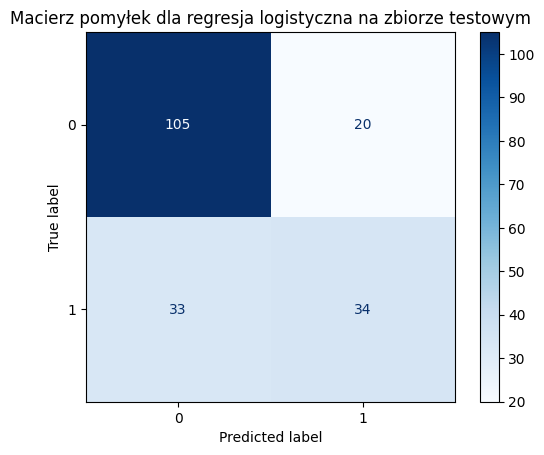

In [15]:
# Twoje rozwiązanie
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
print(f"Najlepszy model: {najlepszy}")
print(f"Wynik CV najlepszego modelu: {wyniki_gs[najlepszy].best_score_:.4f}\n")
acc_test = model_koncowy.score(X_test, y_test)
print(f"Dokładność na zbiorze testowym: {acc_test:.4f}\n")
y_pred = model_koncowy.predict(X_test)
print("Raport klasyfikacji na zbiorze testowym:")
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(model_koncowy, X_test, y_test, cmap="Blues")
plt.title(f"Macierz pomyłek dla {najlepszy} na zbiorze testowym")
plt.show()

In [16]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

1. Wynik na zbiorze testowym wynosi 72.40%, natomiast w walidacji krzyżowej wynosił 77.79%, co daje różnicę około 5.4 pp. Przy tak małym zbiorze danych rozbieżność jest akceptowalna i mieści się w normalnej zmienności próby. Zbiór testowy ma 192 pacjentki, więc jedna osoba odpowiada za ok 0,52pp, a cała różnica między walidacją a testem to około 10 inaczej sklasyfikowanych pacjentek.

2. Recall dla klasy cukrzyca wynosi 0,51, czyli model wykrywa tylko około połowę faktycznie chorych pacjentek. Dla pacjentek oznacza to wysokie ryzyko niewykrycia choroby i braku leczenia u połowy chorych. Accuracy nie jest dobrą metryką w tym zastosowaniu, ponieważ koszt przeoczenia chorej osoby jest znacznie wyższy niż skierowanie zdrowej osoby na dodatkowe badania. Lepiej optymalizować model pod kątem recall lub F1-score.

3. Nie można jednoznacznie wskazać jednego najlepszego algorytmu. Różnice między modelami w czołówce są mniejsze niż odchylenia standardowe ich wyników w walidacji krzyżowej. Różnice te są statystycznie nieistotne.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [17]:
wyniki_gs_recall = {}

for nazwa, model in klasyfikatory.items():
    pipeline = model_z(model)
    gs = GridSearchCV(pipeline, siatki[nazwa], cv=cv, scoring="recall")
    gs.fit(X_train, y_train)
    wyniki_gs_recall[nazwa] = gs
    print(f"{nazwa}:")
    print(f"  Najlepsze parametry: {gs.best_params_}")
    print(f"  Najlepszy wynik CV Recall: {gs.best_score_:.4f}\n")

regresja logistyczna:
  Najlepsze parametry: {'klasyfikator__C': 1}
  Najlepszy wynik CV Recall: 0.5826

kNN:
  Najlepsze parametry: {'klasyfikator__n_neighbors': 3}
  Najlepszy wynik CV Recall: 0.5972

drzewo decyzyjne:
  Najlepsze parametry: {'klasyfikator__max_depth': 4}
  Najlepszy wynik CV Recall: 0.6517

las losowy:
  Najlepsze parametry: {'klasyfikator__max_depth': None, 'klasyfikator__n_estimators': 100}
  Najlepszy wynik CV Recall: 0.5823



In [18]:
najlepszy_recall = max(wyniki_gs_recall, key=lambda n: wyniki_gs_recall[n].best_score_)
model_koncowy_recall = wyniki_gs_recall[najlepszy_recall].best_estimator_
print(f"Najlepszy model pod kątem Recall: {najlepszy_recall}")
y_pred_recall = model_koncowy_recall.predict(X_test)
print("\nRaport klasyfikacji na zbiorze testowym:")
print(classification_report(y_test, y_pred_recall))

Najlepszy model pod kątem Recall: drzewo decyzyjne

Raport klasyfikacji na zbiorze testowym:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       125
           1       0.65      0.61      0.63        67

    accuracy                           0.75       192
   macro avg       0.72      0.72      0.72       192
weighted avg       0.75      0.75      0.75       192



In [19]:
def model_z_indicator(klasyfikator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("klasyfikator", klasyfikator)
    ])

gs_indicator = GridSearchCV(model_z_indicator(LogisticRegression()), siatki["regresja logistyczna"], cv=cv, scoring="accuracy")
gs_indicator.fit(X_train, y_train)
print(f"Regresja logistyczna z flagami braków CV Accuracy: {gs_indicator.best_score_:.4f}")
print(f"Wynik na teście: {gs_indicator.best_estimator_.score(X_test, y_test):.4f}")

Regresja logistyczna z flagami braków CV Accuracy: 0.7691
Wynik na teście: 0.7292


In [20]:
X_zeros = df.drop(columns="outcome")
y_zeros = df["outcome"]
X_train_z, X_test_z, y_train_z, y_test_z = train_test_split(
    X_zeros, y_zeros, test_size=0.25, stratify=y_zeros, random_state=42
)
gs_zeros = GridSearchCV(model_z(LogisticRegression()), siatki["regresja logistyczna"], cv=cv, scoring="accuracy")
gs_zeros.fit(X_train_z, y_train_z)
print(f"Model z zerami CV Accuracy: {gs_zeros.best_score_:.4f}")
print(f"Wynik na teście: {gs_zeros.best_estimator_.score(X_test_z, y_test_z):.4f}")

Model z zerami CV Accuracy: 0.7796
Wynik na teście: 0.7344


1. Po zmianie metryki na recall wybrany model zmienił się z regresji logistycznej na drzewo decyzyjne. Na zbiorze testowym recall dla klasy cukrzyca wzrósł z 0,51 do 0,61, a precision również lekko wzrosło z 0,63 do 0,65.

2. Dodanie flag braków nie poprawiło wyniku walidacji krzyżowej, który spadł z 0,7779 do 0,7691, a na zbiorze testowym zmienił się nieznacznie z 0,7240 na 0,7292. Oznacza to, że sam fakt braku pomiaru insuliny nie niesie istotnej informacji dla modelu.

3. Pozostawienie zer zamiast NaN daje bardzo zbliżone wyniki: 0,7796 w walidacji krzyżowej oraz 0,7344 na zbiorze testowym. Różnica jest mała, ponieważ w najważniejszych dla klasyfikacji cechach, takich jak glukoza, BMI czy wiek, ukrytych braków jest bardzo niewiele, natomiast cechy z dużą liczbą zer, czyli insulina i grubość skóry, mają mniejszy wpływ na decyzję modelu.